In [1]:
# Section 7: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Section 8: Load Dataset
import os

# Try multiple paths to find the dataset
paths_to_try = [
    'Diabetes_prediction.csv',
    '../datasets/Diabetes_prediction.csv',
    'datasets/Diabetes_prediction.csv',
    '../Diabetes_prediction.csv'
]

df = None
for path in paths_to_try:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"Dataset loaded from: {path}")
        break

if df is None:
    raise FileNotFoundError("Could not find Diabetes_prediction.csv. Please check the file path.")

print(f"Shape: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()

Dataset loaded from: Diabetes_prediction.csv
Shape: (1000, 9)

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [3]:
# Section 9: Data Preparation
# Define features and target
feature_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df[feature_cols]
y = df['Diagnosis']

print(f"Features shape: {X.shape}")
print(f"Target distribution:")
print(y.value_counts())
print(f"\nPositive class ratio: {y.mean():.3f}")

# Stratified train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Features shape: (1000, 8)
Target distribution:
Diagnosis
0    694
1    306
Name: count, dtype: int64

Positive class ratio: 0.306

Training set size: 800
Test set size: 200


In [4]:
# Section 10: Model Training - Gini vs Entropy
# Train Decision Tree with Gini criterion
dt_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_gini.fit(X_train, y_train)
gini_acc = accuracy_score(y_test, dt_gini.predict(X_test))

# Train Decision Tree with Entropy criterion
dt_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt_entropy.fit(X_train, y_train)
entropy_acc = accuracy_score(y_test, dt_entropy.predict(X_test))

print(f"Gini Accuracy:    {gini_acc:.4f} ({gini_acc*100:.2f}%)")
print(f"Entropy Accuracy: {entropy_acc:.4f} ({entropy_acc*100:.2f}%)")

Gini Accuracy:    0.5300 (53.00%)
Entropy Accuracy: 0.5550 (55.50%)


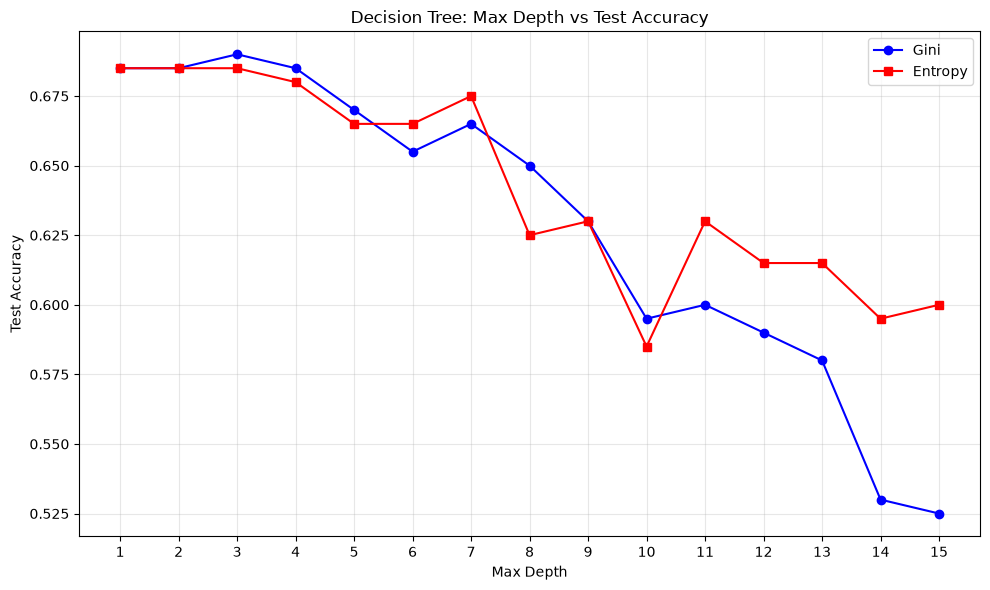

Best depth (Gini): 3, Accuracy: 0.6900


In [5]:
# Section 11: Depth Tuning
# Find best max_depth
depths = range(1, 16)
gini_scores = []
entropy_scores = []

for d in depths:
    dt_g = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    dt_g.fit(X_train, y_train)
    gini_scores.append(accuracy_score(y_test, dt_g.predict(X_test)))

    dt_e = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42)
    dt_e.fit(X_train, y_train)
    entropy_scores.append(accuracy_score(y_test, dt_e.predict(X_test)))

# Plot depth vs accuracy
plt.figure(figsize=(10, 6))
plt.plot(list(depths), gini_scores, marker='o', label='Gini', color='blue')
plt.plot(list(depths), entropy_scores, marker='s', label='Entropy', color='red')
plt.xlabel('Max Depth')
plt.ylabel('Test Accuracy')
plt.title('Decision Tree: Max Depth vs Test Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(list(depths))
plt.tight_layout()
plt.show()

best_depth = depths[gini_scores.index(max(gini_scores))]
print(f"Best depth (Gini): {best_depth}, Accuracy: {max(gini_scores):.4f}")

In [6]:
# Section 12: Final Model and Evaluation
# Train final model with best depth
best_dt = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=42)
best_dt.fit(X_train, y_train)
y_pred = best_dt.predict(X_test)

print("=" * 60)
print("FINAL MODEL EVALUATION (Gini, max_depth={})".format(best_depth))
print("=" * 60)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))

FINAL MODEL EVALUATION (Gini, max_depth=3)

Accuracy: 0.6900

Classification Report:
              precision    recall  f1-score   support

Non-Diabetic       0.70      0.99      0.82       139
    Diabetic       0.33      0.02      0.03        61

    accuracy                           0.69       200
   macro avg       0.51      0.50      0.42       200
weighted avg       0.58      0.69      0.58       200



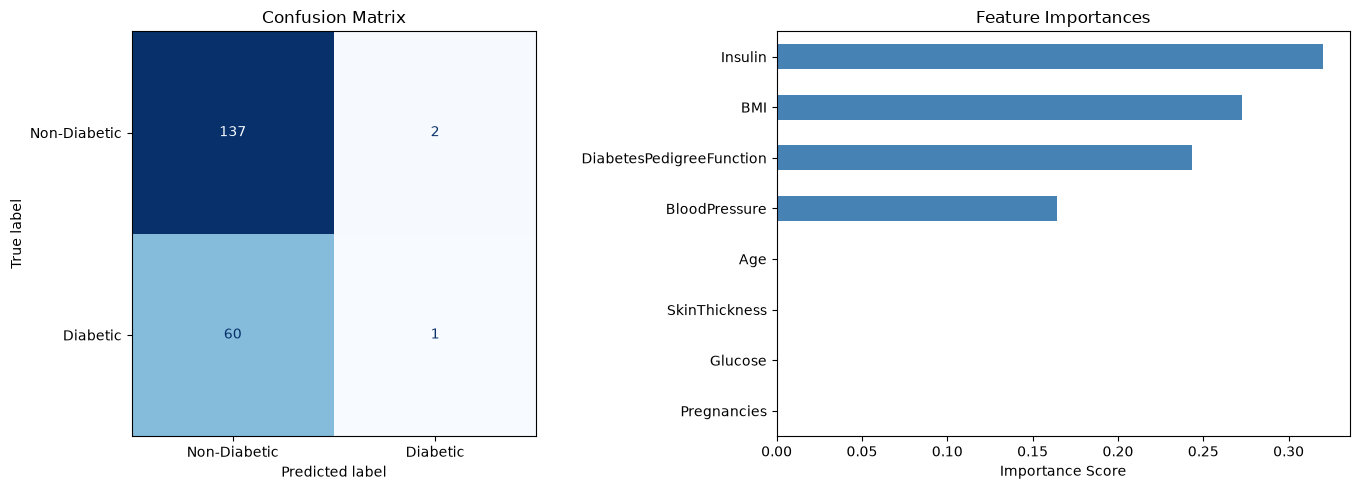

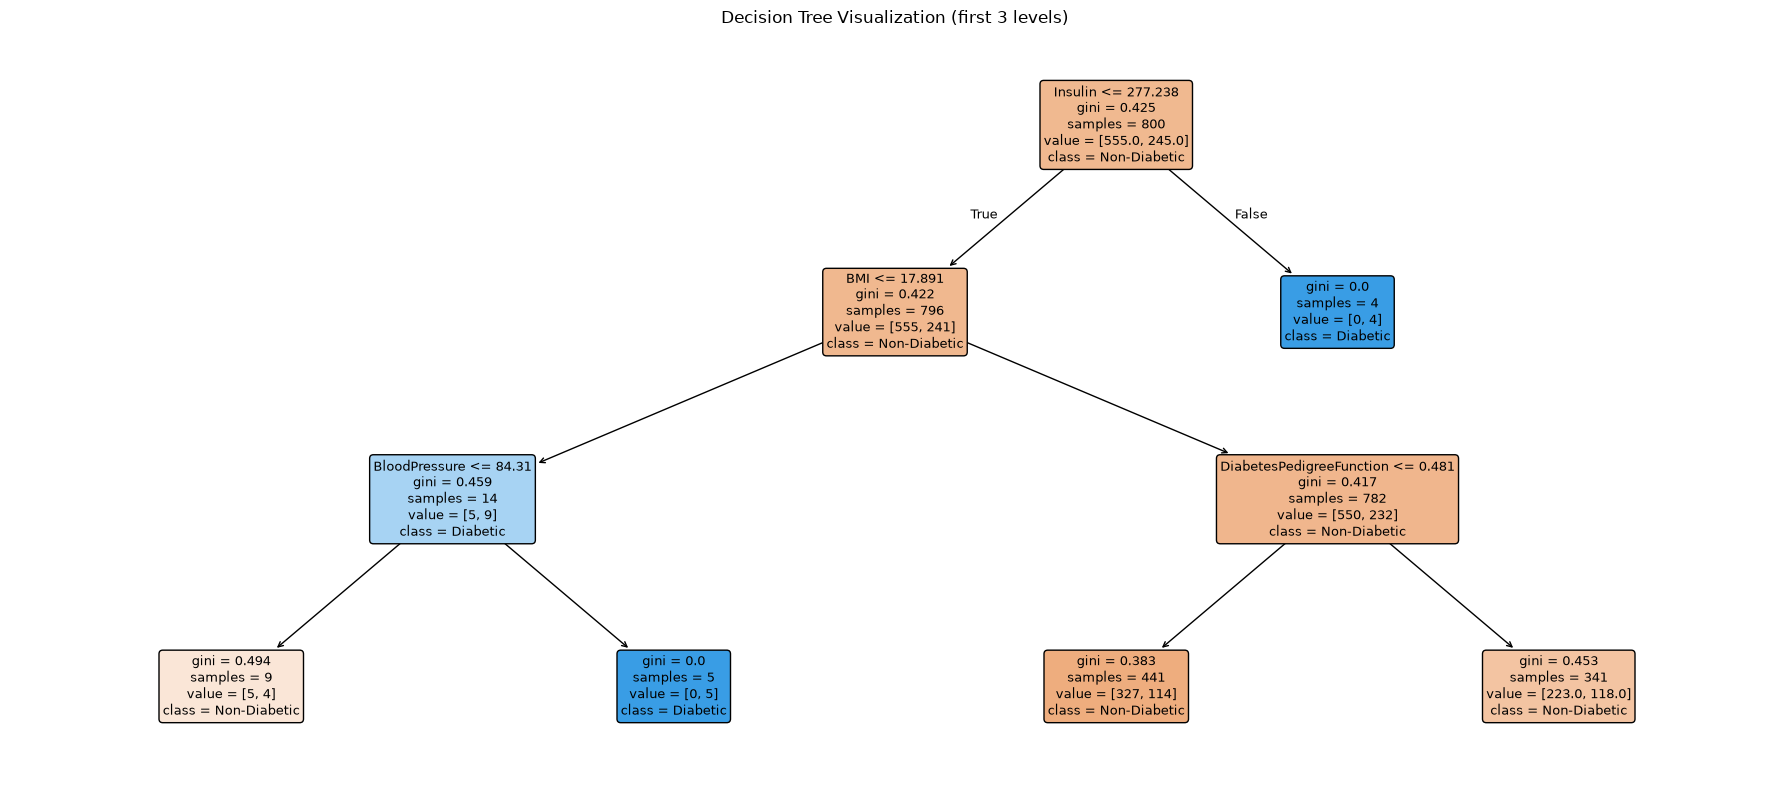

In [7]:
# Section 13: Visualizations
# 1. Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Diabetic', 'Diabetic'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix')

# 2. Feature Importance
importances = pd.Series(best_dt.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Feature Importances')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

# 3. Tree Visualization (limited depth for clarity)
plt.figure(figsize=(18, 8))
plot_tree(best_dt, feature_names=feature_cols,
          class_names=['Non-Diabetic', 'Diabetic'],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title('Decision Tree Visualization (first 3 levels)')
plt.tight_layout()
plt.show()